In [1]:
# Cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pickle, json, os, warnings
warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# Cell 2 - Configuration
SEQ_LENGTH    = 30
BATCH_SIZE    = 64
EPOCHS        = 100
LEARNING_RATE = 0.001
MODEL_NAME    = 'lstm_model'
print(f"Config: SEQ_LENGTH={SEQ_LENGTH}, BATCH_SIZE={BATCH_SIZE}, EPOCHS={EPOCHS}, LR={LEARNING_RATE}")

Config: SEQ_LENGTH=30, BATCH_SIZE=64, EPOCHS=100, LR=0.001


In [3]:
# Cell 3 - Load Data & Feature List
full_df = pd.read_csv('../data/processed/full_engineered.csv', parse_dates=['Date'])
with open('../data/processed/top_features.pkl', 'rb') as f:
    feature_cols = pickle.load(f)
with open('../data/processed/scaler_y.pkl', 'rb') as f:
    scaler_y = pickle.load(f)

target_col = 'Units_Sold_scaled'
print(f"Dataset shape: {full_df.shape}")
print(f"Features: {len(feature_cols)} | Target: {target_col}")

Dataset shape: (89750, 56)
Features: 30 | Target: Units_Sold_scaled


In [4]:
# Cell 4 - Sequence Creation Function
def create_sequences(data, feature_cols, target_col, seq_length=30):
    """Create sliding-window (seq_length, n_features) sequences."""
    X_seqs, y_seqs = [], []
    for sku in sorted(data['SKU_ID'].unique()):
        sku_data = data[data['SKU_ID'] == sku].sort_values('Date')
        X = sku_data[feature_cols].fillna(0).values
        y = sku_data[target_col].values
        for i in range(seq_length, len(X)):
            X_seqs.append(X[i - seq_length:i])
            y_seqs.append(y[i])
    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)

In [5]:
# Cell 5 - Create Time-Based Splits & Sequences
dates = np.sort(full_df['Date'].unique())
n = len(dates)
train_cutoff = dates[int(n * 0.70)]
val_cutoff   = dates[int(n * 0.85)]

train_df = full_df[full_df['Date'] <= train_cutoff]
val_df   = full_df[(full_df['Date'] > train_cutoff) & (full_df['Date'] <= val_cutoff)]
test_df  = full_df[full_df['Date'] > val_cutoff]

X_train, y_train = create_sequences(train_df, feature_cols, target_col, SEQ_LENGTH)
X_val,   y_val   = create_sequences(val_df,   feature_cols, target_col, SEQ_LENGTH)
X_test,  y_test  = create_sequences(test_df,  feature_cols, target_col, SEQ_LENGTH)
print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

X_train: (61500, 30, 30) | X_val: (12000, 30, 30) | X_test: (11750, 30, 30)


In [6]:
# Cell 6 - Build LSTM Model Architecture
def build_lstm_model(seq_length, n_features, units=[128, 64, 32], dropout_rate=0.3):
    """3-layer Stacked LSTM with BatchNorm and Dropout."""
    model = Sequential([
        Input(shape=(seq_length, n_features)),
        LSTM(units[0], return_sequences=True, name='lstm_1'),
        BatchNormalization(),
        Dropout(dropout_rate),
        LSTM(units[1], return_sequences=True, name='lstm_2'),
        BatchNormalization(),
        Dropout(dropout_rate),
        LSTM(units[2], return_sequences=False, name='lstm_3'),
        BatchNormalization(),
        Dropout(dropout_rate / 2),
        Dense(32, activation='relu', name='dense_1'),
        Dense(16, activation='relu', name='dense_2'),
        Dense(1, name='output')
    ], name='LSTM_Model')
    return model

model = build_lstm_model(SEQ_LENGTH, len(feature_cols))
model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='huber', metrics=['mae'])
model.summary()

Model: "LSTM_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 30, 128)             │          81,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 30, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 30, 64)              │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 30, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 145,729 (569.25 KB)

 Trainable params: 145,281 (567.50 KB)

 Non-trainable params: 448 (1.75 KB)

In [7]:
# Cell 7 - Training Callbacks
os.makedirs('../models', exist_ok=True)
callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-6, verbose=1),
    ModelCheckpoint(f'../models/{MODEL_NAME}.keras', monitor='val_loss', save_best_only=True, verbose=1)
]
print("Callbacks configured: EarlyStopping, ReduceLROnPlateau, ModelCheckpoint")

Callbacks configured: EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


In [8]:
# Cell 8 - Train LSTM Model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)
print(f"Training complete. Best val_loss: {min(history.history['val_loss']):.6f}")

Epoch 1/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - loss: 0.0166 - mae: 0.1364
Epoch 1: val_loss improved from None to 0.00891, saving model to ../models/lstm_model.keras

Epoch 1: finished saving model to ../models/lstm_model.keras
961/961 ━━━━━━━━━━━━━━━━━━━━ 164s 155ms/step - loss: 0.0166 - mae: 0.1364 - val_loss: 0.0089 - val_mae: 0.1086 - learning_rate: 0.0010
Epoch 2/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - loss: 0.0095 - mae: 0.1098
Epoch 2: val_loss improved from 0.00891 to 0.00763, saving model to ../models/lstm_model.keras

Epoch 2: finished saving model to ../models/lstm_model.keras
961/961 ━━━━━━━━━━━━━━━━━━━━ 102s 107ms/step - loss: 0.0095 - mae: 0.1098 - val_loss: 0.0076 - val_mae: 0.1002 - learning_rate: 0.0010
Epoch 3/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.0090 - mae: 0.1067
Epoch 3: val_loss improved from 0.00763 to 0.00709, saving model to ../models/lstm_model.keras

Epoch 3: finished saving model to ../models/lstm_model.keras
961/961 ━━━

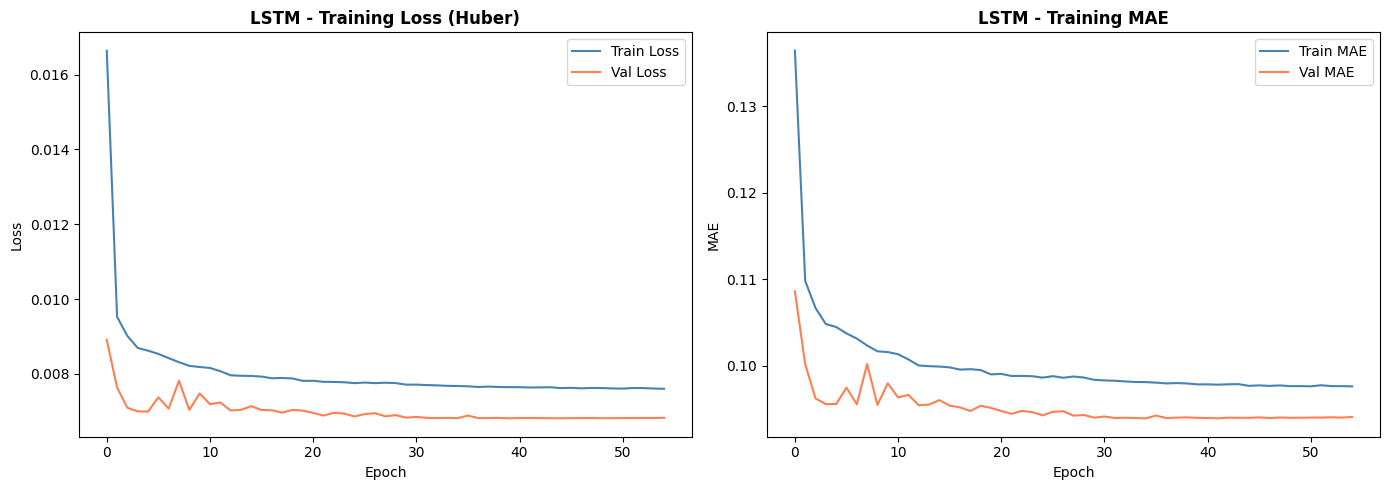

In [9]:
# Cell 9 - Training Curves
os.makedirs('../outputs/plots', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'],     label='Train Loss', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='coral')
axes[0].set_title('LSTM - Training Loss (Huber)', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()
axes[1].plot(history.history['mae'],     label='Train MAE', color='steelblue')
axes[1].plot(history.history['val_mae'], label='Val MAE',   color='coral')
axes[1].set_title('LSTM - Training MAE', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('MAE'); axes[1].legend()
plt.tight_layout()
plt.savefig('../outputs/plots/04_lstm_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Cell 10 - Predictions & Inverse Transform
y_pred_scaled = model.predict(X_test, verbose=0).flatten()
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_true = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()
print(f"Predictions shape: {y_pred.shape} | True shape: {y_true.shape}")

Predictions shape: (11750,) | True shape: (11750,)


In [11]:
# Cell 11 - Evaluation Metrics
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
print(f"\n{'='*40}")
print(f"  LSTM TEST METRICS")
print(f"{'='*40}")
print(f"  RMSE : {rmse:.4f}")
print(f"  MAE  : {mae:.4f}")
print(f"  R²   : {r2:.4f}")
print(f"  MAPE : {mape:.2f}%")
print(f"{'='*40}")


  LSTM TEST METRICS
  RMSE : 6.4628
  MAE  : 5.1269
  R²   : -0.2660
  MAPE : 36.18%


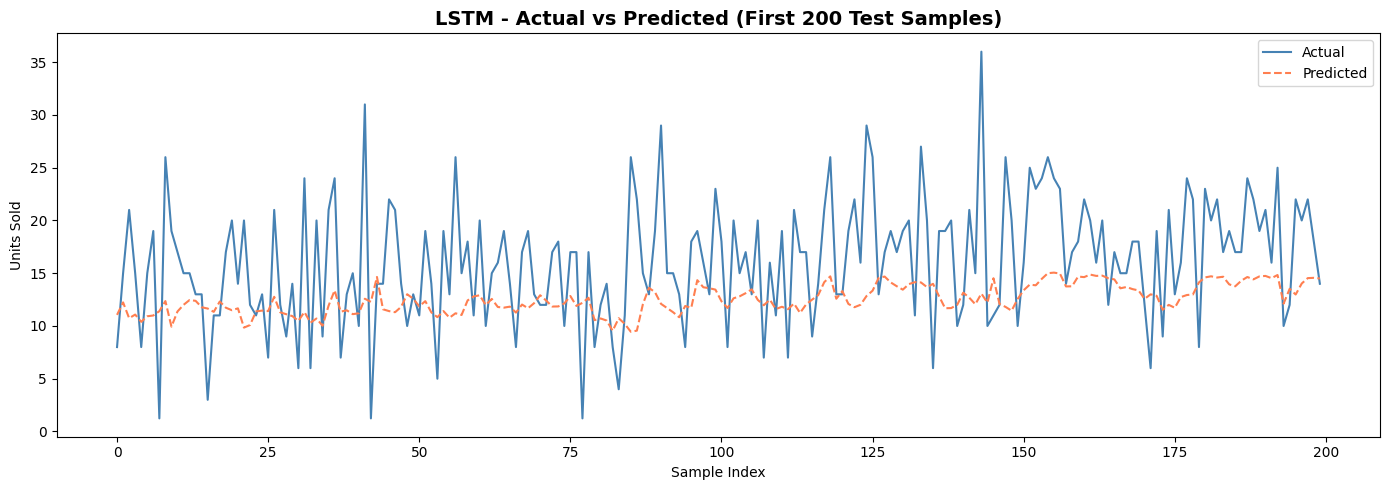

In [12]:
# Cell 12 - Actual vs Predicted Plot
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_true[:200], label='Actual',    color='steelblue', linewidth=1.5)
ax.plot(y_pred[:200], label='Predicted', color='coral',     linewidth=1.5, linestyle='--')
ax.set_title('LSTM - Actual vs Predicted (First 200 Test Samples)', fontsize=14, fontweight='bold')
ax.set_xlabel('Sample Index'); ax.set_ylabel('Units Sold'); ax.legend()
plt.tight_layout()
plt.savefig('../outputs/plots/04_lstm_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

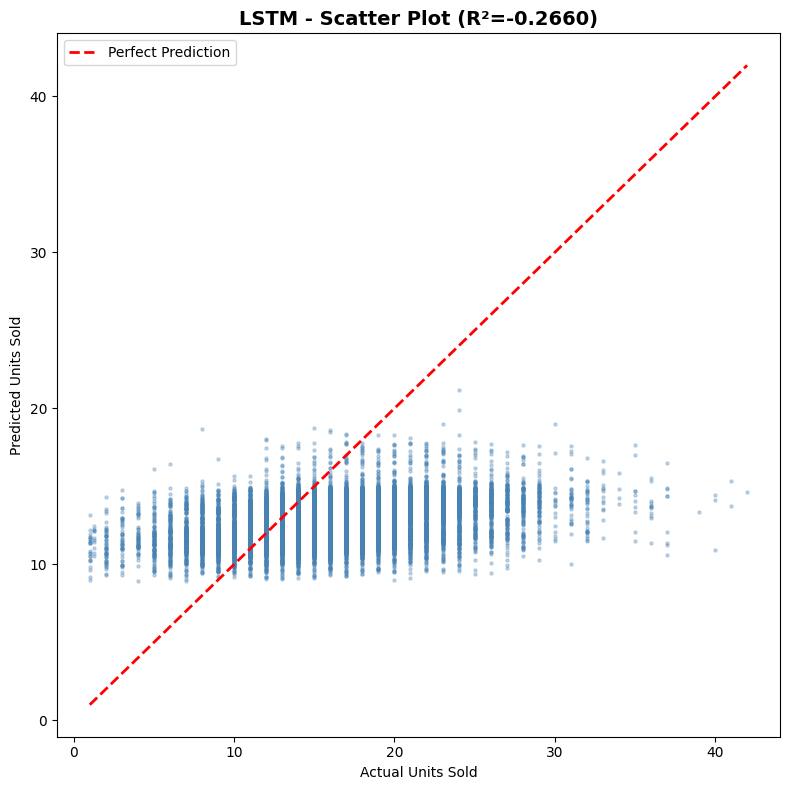

In [13]:
# Cell 13 - Scatter: Actual vs Predicted
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(y_true, y_pred, alpha=0.3, color='steelblue', s=5)
min_v, max_v = min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())
ax.plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=2, label='Perfect Prediction')
ax.set_title(f'LSTM - Scatter Plot (R²={r2:.4f})', fontsize=14, fontweight='bold')
ax.set_xlabel('Actual Units Sold'); ax.set_ylabel('Predicted Units Sold'); ax.legend()
plt.tight_layout()
plt.savefig('../outputs/plots/04_lstm_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Cell 14 - Save Results
os.makedirs('../outputs/reports', exist_ok=True)
lstm_results = {'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r2), 'MAPE': float(mape)}
with open('../outputs/reports/lstm_metrics.json', 'w') as f:
    json.dump(lstm_results, f, indent=2)
np.save('../data/processed/lstm_predictions.npy', y_pred)
np.save('../data/processed/y_true_test.npy', y_true)
print("\n✅ LSTM Model Complete!")
print("Model saved to: models/lstm_model.keras")
print("Metrics saved to: outputs/reports/lstm_metrics.json")


✅ LSTM Model Complete!
Model saved to: models/lstm_model.keras
Metrics saved to: outputs/reports/lstm_metrics.json
